In [37]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import importlib
import improvements_3 

importlib.reload(improvements_3)

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from transformers import BertTokenizer, BertModel

In [2]:
df=pd.read_csv(r"C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\improved_dataset_final.csv")

In [3]:
X = df["final_text"]
y = df["class"]
kflag = df["keyword_flag"]

X_train, X_test, y_train, y_test, kf_train, kf_test = train_test_split(
    X, y, kflag, test_size=0.2, random_state=42, stratify=y
)

In [4]:
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
MAX_LEN = 128

In [5]:
class HybridDataset(Dataset):
    def __init__(self, texts, labels, keyword_flags, tokenizer, max_len):
        self.texts = texts
        self.labels = labels
        self.kflags = keyword_flags
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts.iloc[idx])
        label = self.labels.iloc[idx]
        kflag = self.kflags.iloc[idx]

        encoding = self.tokenizer(
            text,
            padding="max_length",
            truncation=True,
            max_length=self.max_len,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].flatten(),
            "attention_mask": encoding["attention_mask"].flatten(),
            "label": torch.tensor(label, dtype=torch.long),
            "kflag": torch.tensor(kflag, dtype=torch.float)
        }

In [6]:
train_dataset = HybridDataset(X_train, y_train, kf_train, tokenizer, MAX_LEN)
test_dataset  = HybridDataset(X_test, y_test, kf_test, tokenizer, MAX_LEN)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=16)

In [ ]:
class BertBiLSTM(nn.Module):
    def __init__(self):
        super().__init__()

        self.bert = BertModel.from_pretrained("bert-base-uncased")

        self.lstm = nn.LSTM(
            input_size=768,
            hidden_size=128,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(0.3)

        # +1 for keyword_flag
        self.fc = nn.Linear(128*2 + 1, 2)

    def forward(self, input_ids, attention_mask, kflag):
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        sequence_output = outputs.last_hidden_state

        lstm_out, _ = self.lstm(sequence_output)

        pooled = lstm_out[:, 0, :]

        # concatenate keyword flag
        combined = torch.cat((pooled, kflag.unsqueeze(1)), dim=1)

        out = self.dropout(combined)
        return self.fc(out)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = BertBiLSTM().to(device)


classes = np.unique(y_train)
weights = compute_class_weight("balanced", classes=classes, y=y_train)
weights = torch.tensor(weights, dtype=torch.float).to(device)

criterion = nn.CrossEntropyLoss(weight=weights)
optimizer = torch.optim.Adam(model.parameters(), lr=2e-5)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2884.21it/s]
BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [9]:
def train(model, loader):
    model.train()
    total_loss = 0

    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["label"].to(device)
        kflag = batch["kflag"].to(device)

        outputs = model(input_ids, attention_mask, kflag)

        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)

In [10]:
def evaluate(model, loader):
    model.eval()
    preds, true = [], []

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)
            kflag = batch["kflag"].to(device)

            outputs = model(input_ids, attention_mask, kflag)
            pred = torch.argmax(outputs, dim=1)

            preds.extend(pred.cpu().numpy())
            true.extend(labels.cpu().numpy())

    return np.array(preds), np.array(true)

In [11]:
#train lama baseline bert ye5alas
for epoch in range(3):
    loss = train(model, train_loader)
    preds, true = evaluate(model, test_loader)

    print(f"Epoch {epoch+1} Loss: {loss:.4f}")

    print("Accuracy:", accuracy_score(true, preds))
    print("Precision:", precision_score(true, preds))
    print("Recall:", recall_score(true, preds))
    print("F1:", f1_score(true, preds))

Epoch 1 Loss: 0.5262
Accuracy: 0.7934443288241415
Precision: 0.8567713542708542
Recall: 0.7714337175792507
F1: 0.8118661738223865
Epoch 2 Loss: 0.4384
Accuracy: 0.8030176899063476
Precision: 0.8762081019946535
Recall: 0.767471181556196
F1: 0.8182429188670187
Epoch 3 Loss: 0.4216
Accuracy: 0.8061394380853277
Precision: 0.8897105429959856
Recall: 0.7584654178674352
F1: 0.8188624210014585


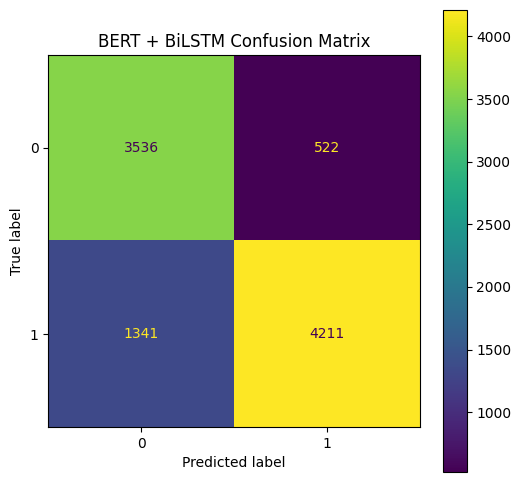

In [14]:
#eval + confusion matrix
cm = confusion_matrix(true, preds)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)

fig, ax = plt.subplots(figsize=(6,6))
disp.plot(ax=ax)

plt.title("BERT + BiLSTM Confusion Matrix")
plt.show()

In [ ]:
#error analysis
error_df = pd.DataFrame({
    "text": X_test.reset_index(drop=True),
    "true": true,
    "predicted": preds
})

In [16]:
fp = error_df[
    (error_df["true"] == 0) &
    (error_df["predicted"] == 1)
]

print("False Positives:", len(fp))
fp.head(10)

False Positives: 522


,text,true,predicted
10,you are hotxa0xa0 damn,0,1
17,momma said no pussy cat inside my doghouse,0,1
37,every single thing out of your mouth is taquiy...,0,1
51,wa a pedophile,0,1
66,rt hi ho hi ho it off to work we go it militar...,0,1
75,before and after i started playing flappy bird...,0,1
80,cute dumb female trash,0,1
113,tranny,0,1
114,the main problem with the vatican is that they...,0,1
115,from the look of my twitter feed this morning ...,0,1


In [18]:
for _, row in fn.head(5).iterrows():
    print("TEXT:", row["text"])
    print("TRUE:", row["true"], "| PRED:", row["predicted"])
    print("-"*60)

TEXT: i m not sexist but i m old hat cleaning the car a bloke job cutting the grass a bloke job we have a dish
TRUE: 1 | PRED: 0
------------------------------------------------------------
TEXT: perverted idiot it is time to you for the rest of the night
TRUE: 1 | PRED: 0
------------------------------------------------------------
TEXT: i m not sexist but diva match annoy me and tag team diva match
TRUE: 1 | PRED: 0
------------------------------------------------------------
TEXT: most of these people are follower of follower of truth but they themselves are still nigger their outlook mind amp all
TRUE: 1 | PRED: 0
------------------------------------------------------------
TEXT: and are faggot kbye
TRUE: 1 | PRED: 0
------------------------------------------------------------


In [19]:
for _, row in fp.head(5).iterrows():
    print("TEXT:", row["text"])
    print("TRUE:", row["true"], "| PRED:", row["predicted"])
    print("-"*60)

TEXT: you are hotxa0xa0 damn
TRUE: 0 | PRED: 1
------------------------------------------------------------
TEXT: momma said no pussy cat inside my doghouse
TRUE: 0 | PRED: 1
------------------------------------------------------------
TEXT: every single thing out of your mouth is taquiyya blocked
TRUE: 0 | PRED: 1
------------------------------------------------------------
TEXT: wa a pedophile
TRUE: 0 | PRED: 1
------------------------------------------------------------
TEXT: rt hi ho hi ho it off to work we go it militarymondaysupport a military organization today
TRUE: 0 | PRED: 1
------------------------------------------------------------


In [17]:
fn = error_df[
    (error_df["true"] == 1) &
    (error_df["predicted"] == 0)
]

print("False Negatives:", len(fn))
fn.head(10)

False Negatives: 1341


,text,true,predicted
18,i m not sexist but i m old hat cleaning the ca...,1,0
39,perverted idiot it is time to you for the rest...,1,0
46,i m not sexist but diva match annoy me and tag...,1,0
58,most of these people are follower of follower ...,1,0
87,and are faggot kbye,1,0
88,bahahaha oh my gosh kat ha no idea none mkr,1,0
92,buddhist teaching doe not contain violence hat...,1,0
93,all i got for these hoe is dick duct tape and ...,1,0
95,a a girlfriend i am never getting close to my ...,1,0
98,nnyou look like brian scalabrines brother thought,1,0


In [20]:
#testing on 2 external datasets
df_1=pd.read_csv(r"C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\labeled_data.csv")
df_2=pd.read_csv(r"C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\train_E6oV3lV.csv")

In [21]:
import re
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

lemmatizer = WordNetLemmatizer()

def full_preprocess(text):
    text = str(text).lower()
    
    # Step 2: remove URLs, mentions, keep hashtag words
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    
    # Step 3: normalize elongated words
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    
    # Step 4: remove punctuation + extra spaces
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    
    # Step 5: lemmatization
    tokens = word_tokenize(text)
    text = " ".join([lemmatizer.lemmatize(word) for word in tokens])
    
    return text

In [38]:
from improvements_3 import fix_obfuscation, normalize_slang, keyword_flag, mask_keywords

In [39]:
def prepare_external(df, text_col):

    df["clean_text"] = df[text_col].apply(full_preprocess)

    df["text_obf"] = df["clean_text"].apply(fix_obfuscation)

    df["text_slang"] = df["text_obf"].apply(normalize_slang)

    df["text_masked"] = df["text_slang"].apply(mask_keywords)

    df["keyword_flag"] = df["text_slang"].apply(keyword_flag)

    df["final_text"] = df["text_masked"]

    return df

In [40]:
df_1 = prepare_external(df_1, "tweet")
df_2 = prepare_external(df_2, "tweet")

In [41]:
df_1["class_binary"] = df_1["class"].apply(lambda x: 0 if x == 2 else 1)

In [42]:
df_2["class_binary"] = df_2["label"]

In [43]:
ext_dataset1 = HybridDataset(
    df_1["final_text"],
    df_1["class_binary"],
    df_1["keyword_flag"],
    tokenizer,
    MAX_LEN
)

ext_dataset2 = HybridDataset(
    df_2["final_text"],
    df_2["class_binary"],
    df_2["keyword_flag"],
    tokenizer,
    MAX_LEN
)

In [44]:
ext_loader1 = DataLoader(ext_dataset1, batch_size=16)
ext_loader2 = DataLoader(ext_dataset2, batch_size=16)

In [45]:
preds1, true1 = evaluate(model, ext_loader1)

print("=== DAVIDSON RESULTS ===")

print("Accuracy :", accuracy_score(true1, preds1))
print("Precision:", precision_score(true1, preds1))
print("Recall   :", recall_score(true1, preds1))
print("F1       :", f1_score(true1, preds1))

=== DAVIDSON RESULTS ===
Accuracy : 0.8450550780777145
Precision: 0.9533174843311001
Recall   : 0.8556741028128031
F1       : 0.9018605602126355


In [46]:
preds2, true2 = evaluate(model, ext_loader2)

print("=== TSA RESULTS ===")

print("Accuracy :", accuracy_score(true2, preds2))
print("Precision:", precision_score(true2, preds2))
print("Recall   :", recall_score(true2, preds2))
print("F1       :", f1_score(true2, preds2))

=== TSA RESULTS ===
Accuracy : 0.8661848445028472
Precision: 0.16650278597181253
Recall   : 0.22658340767172166
F1       : 0.19195163423389383
